# Random Forest Regression

## Objective
Predict Melbourne house prices using a Random Forest Regression model.

## Steps
1. Load and inspect the dataset.
2. Select features and target.
3. Split data into training and testing sets.
4. Handle missing values using median imputation.
5. Train a Random Forest Regression model.
6. Evaluate performance using MAE, RMSE, and R² Score.
7. Compare the results with previous models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
data = pd.read_csv("../01-Data-Preparation/melb_data.csv")

data.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [4]:
print("Dataset shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Dataset shape: (13580, 21)

Missing values:
Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
dtype: int64


In [5]:
features = [
    "Rooms",
    "Distance",
    "Bedroom2",
    "Bathroom",
    "Car",
    "Landsize",
    "BuildingArea",
    "YearBuilt"
]

X = data[features]
y = data["Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (13580, 8)
Target shape: (13580,)


In [6]:
valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Features shape after removing missing prices:", X.shape)
print("Target shape after removing missing prices:", y.shape)

Features shape after removing missing prices: (13580, 8)
Target shape after removing missing prices: (13580,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 10864
Testing samples: 2716


In [8]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Training data shape:", X_train_imputed.shape)
print("Testing data shape:", X_test_imputed.shape)

Training data shape: (10864, 8)
Testing data shape: (2716, 8)


In [9]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_imputed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [10]:
y_pred = model.predict(X_test_imputed)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Error"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

comparison["Absolute Error"] = comparison["Error"].abs()

comparison.head(10)

,Actual Price,Predicted Price,Error,Absolute Error
0,2600000.0,1.620410e+06,9.795900e+05,9.795900e+05
1,620000.0,5.659550e+05,5.404500e+04,5.404500e+04
2,1000000.0,1.045565e+06,-4.556500e+04,4.556500e+04
3,430000.0,6.059900e+05,-1.759900e+05,1.759900e+05
4,392250.0,1.501375e+06,-1.109125e+06,1.109125e+06
5,700000.0,7.892301e+05,-8.923014e+04,8.923014e+04
6,439000.0,5.267679e+05,-8.776788e+04,8.776788e+04
7,2236000.0,1.935795e+06,3.002050e+05,3.002050e+05
8,671000.0,6.626300e+05,8.370000e+03,8.370000e+03
9,1870000.0,1.222485e+06,6.475150e+05,6.475150e+05


In [11]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

MAE: 238562.16
RMSE: 366761.22
R² Score: 0.6614


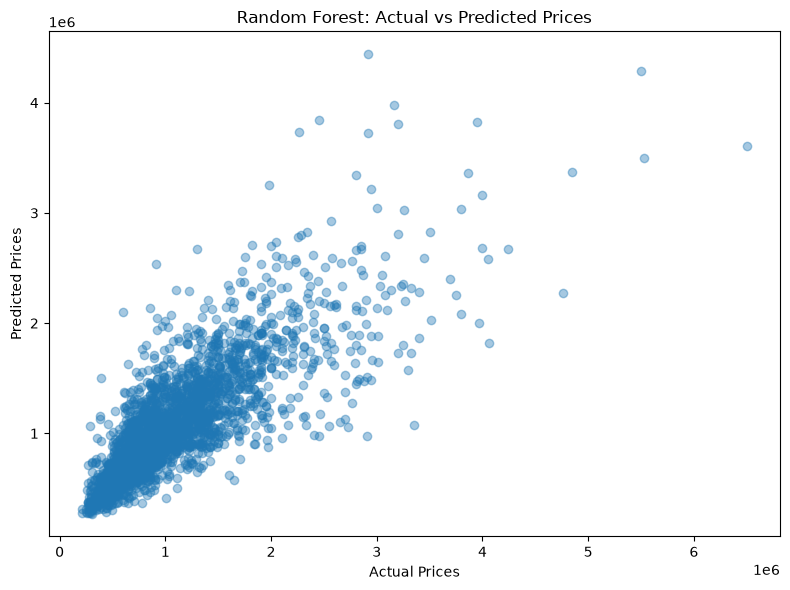

In [12]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Random Forest: Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

        Feature  Importance
1      Distance    0.275839
0         Rooms    0.229321
5      Landsize    0.196752
6  BuildingArea    0.116507
7     YearBuilt    0.085025
3      Bathroom    0.052639
4           Car    0.032780
2      Bedroom2    0.011136


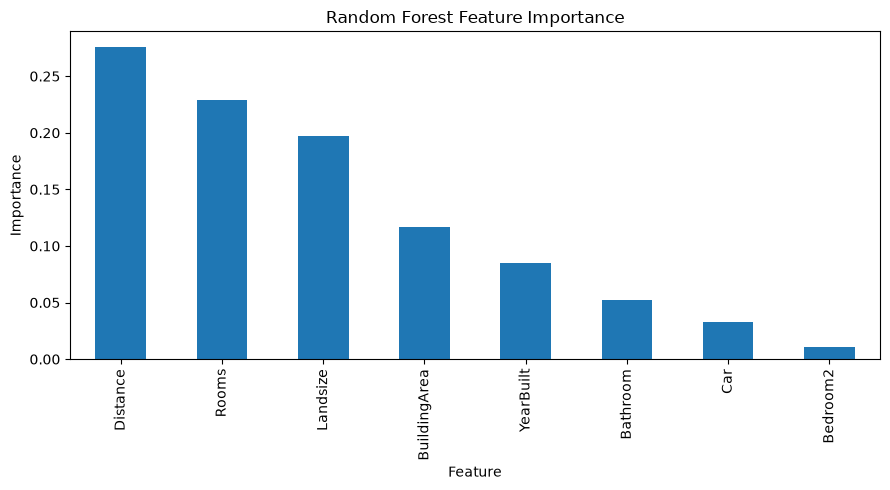

In [13]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(9, 5)
)

plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

## Conclusion

- Trained a Random Forest Regression model using eight numerical features.
- Handled missing values using median imputation.
- Evaluated the model using MAE, RMSE, and R² Score.
- Visualized actual versus predicted prices.
- Examined feature importance.

### Key Learning

Random Forest combines predictions from multiple decision trees. It can capture nonlinear relationships and may generalize better than a single decision tree, but its performance must be verified using test data.

### Next Step

Compare Random Forest with Linear Regression and Decision Tree Regression using the same test split and evaluation metrics.

In [14]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        328186.53,
        321566.26,
        mae
    ],
    "RMSE": [
        473437.82,
        496136.12,
        rmse
    ],
    "R2 Score": [
        0.4357,
        0.3803,
        r2
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,328186.530000,473437.820000,0.435700
1,Decision Tree,321566.260000,496136.120000,0.380300
2,Random Forest,238562.159166,366761.218798,0.661357
